# Finite Elements for Contaminant Transport

## Problem description
In this notebook, code is provided to solve the advection/diffusion/reaction equation for transport of a contaminant in groundwater after an industrial spill. We consider an underground sand channel as aquifer. The aquifer is a buried meandering river and therefore has an irregular shape over which an unstructured mesh is needed. In the middle of the sand river, there is a clay island which is considered impermeable and splits the channel into two arms that again merge downstream. The aquifer in modeled in 2D, as a horizontal section, which implies uniform thickness of the aquifer and a planar flow profile. 

The advection/diffusion/reaction equation is given by:

$$
\frac{\partial c}{\partial t} = \kappa \nabla\cdot\nabla c - \mathbf{v}\cdot\nabla c - r c
$$

Where 
- $c$ is the unknown concentration field, dependent on space ($x$, $y$) and time ($t$)
- $\kappa$ is the diffusivity, assumed to be constant
- $\mathbf{v}$ is the groundwater velocity, satisfying $\nabla\cdot \mathbf{v} = 0$
- $r$ is a reaction rate, representing exponential decay of the contaminant

We use $\nabla a$ for the gradient of the scalar (results in a vector), and $\nabla\cdot\mathbf{q}$ for the divergence of a vector $\mathbf{q}$ (results in a scalar):

$$
\nabla c = \begin{bmatrix} \partial c/\partial x \\ \partial c/\partial y \end{bmatrix}, \qquad 
\nabla \cdot \mathbf{q} = \frac{\partial q_x}{\partial x} + \frac{\partial q_y}{\partial y}
$$

The two-dimensional domain $\Omega$ has a boundary $\Gamma$ that can be subdivided in a part where Dirichlet boundary conditions are applied $\Gamma_D$ and a part where Neumann boundary conditions are applied $\Gamma_N$. The Neumann boundary conditions define a contaminant flux of magnitude $q(x,y,t)$ into the domain:

$$
\kappa\nabla c\cdot \mathbf{n} = q
$$

where $\mathbf{n}$ is the outward pointing normal to the boundary. 

> **Task 1**
>
> To solve the problem finite element discretization is applied in 2D space, while time is discretized with backward Euler time stepping. A semi-discrete form is obtained by applying the finite element discretization, while leaving the time derivative untouched. The semi-discrete form for this problem is:
>
> $$
> \mathbf{M}\frac{\partial\mathbf{c}}{\partial t} + \mathbf{Kc} + \mathbf{Cc} + \mathbf{Rc} = \mathbf{f}
> $$
>
> where $\mathbf{M}$, $\mathbf{K}$, $\mathbf{C}$ and $\mathbf{R}$ are matrices and $\mathbf{c}$ is a vector with concentration values at the nodes. For now, $\mathbf{c}$ is still a continuous function of time.
>
> Starting from the strong form of the advection/diffusion/reaction equation, derive expressions for finite element matrices $\mathbf{M}$, $\mathbf{K}$, $\mathbf{C}$ and $\mathbf{R}$.
>
> **Hint:**
>
> - The matrix $\mathbf{K}$ should have the same form as the matrix for the 2D Poisson equation as derived [in the book](https://mude.citg.tudelft.nl/book/2026/fem/poisson2d.html) (except that $\kappa$ takes the place of $\nu$).
> - The concentration depends on time and space $c \equiv c(x,y,t)$. Spatial discretization is done with finite element shape functions, while time-dependence is in the nodal degrees of freedom: $c(x,y,t) = \mathbf{N}(x,y)\mathbf{c}(t)$.


### Solution Task 1

**Step 0 – Strong form (all terms on the left)**

$$
\frac{\partial c}{\partial t} - \kappa \nabla\cdot\nabla c + \mathbf{v}\cdot\nabla c + r c = 0 \quad \text{in } \Omega,
\qquad c = \bar c \ \text{on } \Gamma_D, \qquad \kappa\nabla c\cdot\mathbf{n} = q \ \text{on } \Gamma_N
$$

**Step 1 – Multiply by a weight function $w$ (with $w=0$ on $\Gamma_D$) and integrate over $\Omega$**

$$
\int_\Omega w\frac{\partial c}{\partial t}\,d\Omega
- \int_\Omega w\,\kappa\nabla\cdot\nabla c\,d\Omega
+ \int_\Omega w\,\mathbf{v}\cdot\nabla c\,d\Omega
+ \int_\Omega w\,r c\,d\Omega = 0 \qquad \forall w
$$

**Step 2 – Integrate the diffusion term by parts** (product rule + divergence theorem), so that only first derivatives remain:

$$
-\int_\Omega w\,\kappa\nabla\cdot\nabla c\,d\Omega
= \int_\Omega \kappa\,\nabla w\cdot\nabla c\,d\Omega - \oint_\Gamma w\,\kappa\nabla c\cdot\mathbf{n}\,d\Gamma
$$

On $\Gamma_D$: $w=0$. On $\Gamma_N$: $\kappa\nabla c\cdot\mathbf{n}=q$. The advection term only has first derivatives and is not integrated by parts.

**Step 3 – Weak form**

$$
\int_\Omega w\frac{\partial c}{\partial t}\,d\Omega
+ \int_\Omega \kappa\,\nabla w\cdot\nabla c\,d\Omega
+ \int_\Omega w\,\mathbf{v}\cdot\nabla c\,d\Omega
+ \int_\Omega r\,w\,c\,d\Omega
= \int_{\Gamma_N} w\,q\,d\Gamma
$$

**Step 4 – Discretize** (space in $\mathbf{N}$, time in $\mathbf{c}$), Galerkin: same shape functions for $w$

$$
c = \mathbf{N}\mathbf{c}(t), \quad \frac{\partial c}{\partial t} = \mathbf{N}\frac{\partial \mathbf{c}}{\partial t}, \quad \nabla c = \mathbf{B}\mathbf{c}, \quad \mathbf{v}\cdot\nabla c = \mathbf{v}^T\mathbf{B}\mathbf{c}, \quad
w = \mathbf{w}^T\mathbf{N}^T, \quad (\nabla w)^T = \mathbf{w}^T\mathbf{B}^T
$$

with $\mathbf{B} = \begin{bmatrix}\partial\mathbf{N}/\partial x \\ \partial\mathbf{N}/\partial y\end{bmatrix}$ ($2\times n$).

**Step 5 – Substitute and factor out $\mathbf{w}^T$** (must hold for all $\mathbf{w}$, so the bracket is zero):

$$
\mathbf{w}^T\Big[
\underbrace{\int_\Omega \mathbf{N}^T\mathbf{N}\,d\Omega}_{\mathbf{M}}\frac{\partial\mathbf{c}}{\partial t}
+ \underbrace{\int_\Omega \kappa\,\mathbf{B}^T\mathbf{B}\,d\Omega}_{\mathbf{K}}\mathbf{c}
+ \underbrace{\int_\Omega \mathbf{N}^T\mathbf{v}^T\mathbf{B}\,d\Omega}_{\mathbf{C}}\mathbf{c}
+ \underbrace{\int_\Omega r\,\mathbf{N}^T\mathbf{N}\,d\Omega}_{\mathbf{R}}\mathbf{c}
- \underbrace{\int_{\Gamma_N}\mathbf{N}^T q\,d\Gamma}_{\mathbf{f}}
\Big] = 0
$$

**Result**

$$
\mathbf{M} = \int_\Omega \mathbf{N}^T\mathbf{N}\,d\Omega, \quad
\mathbf{K} = \int_\Omega \kappa\,\mathbf{B}^T\mathbf{B}\,d\Omega, \quad
\mathbf{C} = \int_\Omega \mathbf{N}^T\mathbf{v}^T\mathbf{B}\,d\Omega, \quad
\mathbf{R} = \int_\Omega r\,\mathbf{N}^T\mathbf{N}\,d\Omega = r\mathbf{M}, \quad
\mathbf{f} = \int_{\Gamma_N}\mathbf{N}^T q\,d\Gamma
$$

$\mathbf{M}$, $\mathbf{K}$ and $\mathbf{R}$ are symmetric; $\mathbf{C}$ is not. In practice each integral is evaluated per element and assembled into the global matrix.

## Load mesh and velocity field

The domain of interest is an aquifer, with embedded impermeable object. Only the permeable domain is meshed, resulting in a non-trivial geometry that is discretized with triangular elements. In the code block below, the provided mesh file is read using code from *mesh_utils.py*. A precomputed velocity field is also read from file. The velocity field is visualized on the mesh with a function from *postprocess.py*. The impermeable object appears as a gap in the mesh. 

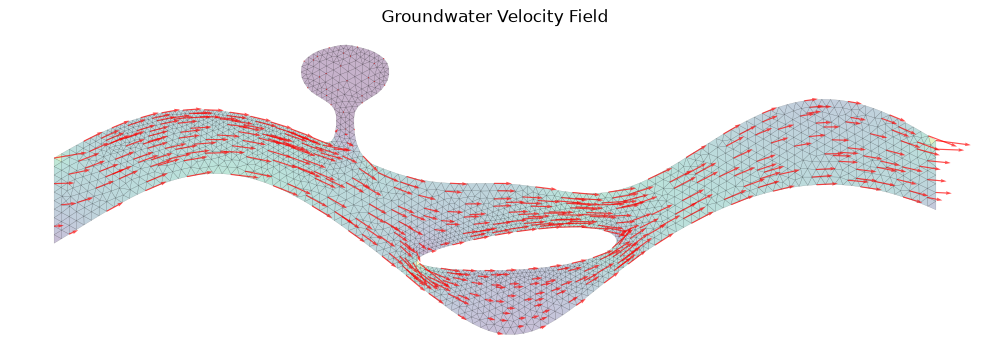

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse
import os
from urllib.request import urlretrieve

# import local py-files
import postprocess as pp
import mesh_utils as mu

%matplotlib inline

# Download mesh and data files
def findfile(fname):
    if not os.path.isfile(fname):
        print(f"Downloading {fname}...")
        urlretrieve('https://github.com/TUDelft-MUDE/source-files/raw/main/file/GA2.2/'+fname, fname)

findfile('channel_aquifer.msh')
findfile('velocity_elems_channel.csv')

# Read mesh file
nodes, connectivity, edge_connectivity = mu.read_gmsh('channel_aquifer.msh')

# Load eleemnt-wise velocity field and visualize it on the mesh
velocities = np.loadtxt('velocity_elems_channel.csv', delimiter=',')
pp.plot_velocity_field(nodes, connectivity, velocities, scale_factor = 2e8 )



## Finite element functions

The main building blocks for the finite element simulation are provided in the code block below.

> **Task 2** 
>
> Look at how the different matrices are implemented and compare the implementations to the expressions you have derived. Only three of the four matrices $\mathbf{K}$, $\mathbf{R}$, $\mathbf{C}$ and $\mathbf{M}$ are defined here. Which of the three definitions can be used to also compute the missing one? 

In [4]:
# Function makes the coefficients of shape functions for a 3-node triangle with given node coordinates
def get_shape_functions_T3(n1, n2, n3):
    coordinate_matrix = np.ones((3,3))
    coeffs = np.zeros((3,3))
    
    coordinate_matrix[0, 1] = n1[0]
    coordinate_matrix[0, 2] = n1[1]
    coordinate_matrix[1, 1] = n2[0]
    coordinate_matrix[1, 2] = n2[1]
    coordinate_matrix[2, 1] = n3[0]
    coordinate_matrix[2, 2] = n3[1]
    
    c_inv = np.linalg.inv(coordinate_matrix)
    coeffs[0] = np.dot(c_inv, (1,0,0))
    coeffs[1] = np.dot(c_inv, (0,1,0))
    coeffs[2] = np.dot(c_inv, (0,0,1))
    
    return coeffs

# Function creates the derivative shape function vector (B) of the given 3-node triangle
def get_B_matrix(n1, n2, n3):
    coeffs = get_shape_functions_T3(n1, n2, n3)
    B_matrix = [[coeffs[0][1], coeffs[1][1], coeffs[2][1]], 
                [coeffs[0][2], coeffs[1][2], coeffs[2][2]]]
    return np.array(B_matrix)

# Function returns the area of the triangle
def get_area(n1, n2, n3):
    u = n3-n1
    v = n2-n1
    return abs(u[0]*v[1]-u[1]*v[0])/2

# Evaluate shape function matrix at given coordinates
def evaluate_N_matrix(ipcoords, n1, n2, n3):    
    coeffs = get_shape_functions_T3(n1, n2, n3)
    x = ipcoords[0]
    y = ipcoords[1]
    N_matrix = [[coeffs[0][0] + coeffs[0][1]*x + coeffs[0][2]*y, 
                 coeffs[1][0] + coeffs[1][1]*x + coeffs[1][2]*y, 
                 coeffs[2][0] + coeffs[2][1]*x + coeffs[2][2]*y]]
    return np.array(N_matrix)

# DIFFUSION: Function returns the K-matrix for a single element
def get_element_K(n1, n2, n3, nu):
    B = get_B_matrix(n1, n2, n3)
    element_area = get_area(n1, n2, n3)
    return element_area * nu * B.T @ B

# ADVECTION: Function returns the C-matrix for a single element
# Advection matrix using simple integration (assumes constant velocity in element)
def get_element_C(n1, n2, n3, velocity):
    B = get_B_matrix(n1, n2, n3)
    element_area = get_area(n1, n2, n3)
    centroid = (n1 + n2 + n3) / 3
    N_centroid = evaluate_N_matrix(centroid, n1, n2, n3)
    
    v_matrix = np.array(velocity).reshape((1,2))
    C_el = N_centroid.T @ v_matrix @ B * element_area
    
    return C_el

# MASS: Function returns the M-matrix for a single element
def get_element_M(n1, n2, n3):
    M_el = np.zeros((3,3))
    element_area = get_area(n1, n2, n3)    
    integration_locations = [(n1+n2)/2, (n2+n3)/2, (n3+n1)/2]
    integration_weights = [element_area/3, element_area/3, element_area/3]
    for x_ip, w_ip in zip(integration_locations, integration_weights):
        N_local = evaluate_N_matrix(x_ip, n1, n2, n3)
        M_el += N_local.T @ N_local * w_ip
    return M_el

# Assembly functions
def get_global_K(nodes, connectivity, nu):
    n_DOF = len(nodes)
    K = np.zeros((n_DOF, n_DOF))
    for elnodes in connectivity:
        K_el = get_element_K(nodes[elnodes[0]], nodes[elnodes[1]], nodes[elnodes[2]], nu)
        K[np.ix_(elnodes,elnodes)] += K_el
    return K

def get_global_C(nodes, connectivity, velocities):
    n_DOF = len(nodes)
    C = np.zeros((n_DOF, n_DOF))
    for elnodes, element_velocity in zip(connectivity, velocities):
        C_el = get_element_C(nodes[elnodes[0]], nodes[elnodes[1]], nodes[elnodes[2]], element_velocity)
        C[np.ix_(elnodes,elnodes)] += C_el
    return C

def get_global_M(nodes, connectivity):
    n_DOF = len(nodes)
    M = np.zeros((n_DOF, n_DOF))
    for elnodes in connectivity:
        M_el = get_element_M(nodes[elnodes[0]], nodes[elnodes[1]], nodes[elnodes[2]])
        M[np.ix_(elnodes,elnodes)] += M_el
    return M

def get_global_f(nodes, elems, q, xmin=-1e6, xmax=1e6):
    n_DOF = len(nodes)
    f = np.zeros(n_DOF)
    for elem in elems:
        xcentroid = ( nodes[elem[0]][0] + nodes[elem[1]][0] ) / 2
        if xcentroid > xmin and xcentroid < xmax:
            length = np.linalg.norm(nodes[elem[0]]-nodes[elem[1]])
            f[elem] += q*length/2
    return f


### Solution Task 2

**Shape functions (`get_shape_functions_T3`)**

For a 3-node triangle each shape function is linear: $N_i(x,y) = a_i + b_i x + c_i y$. The coefficients follow from the requirement $N_i(x_j,y_j) = \delta_{ij}$ (1 at its own node, 0 at the other two):

$$
\begin{bmatrix} 1 & x_1 & y_1 \\ 1 & x_2 & y_2 \\ 1 & x_3 & y_3 \end{bmatrix}
\begin{bmatrix} a_i \\ b_i \\ c_i \end{bmatrix} = \mathbf{e}_i
\quad\Rightarrow\quad
\begin{bmatrix} a_i \\ b_i \\ c_i \end{bmatrix} = \mathbf{X}^{-1}\mathbf{e}_i
$$

This is exactly what the code does with `c_inv` and the unit vectors `(1,0,0)`, `(0,1,0)`, `(0,0,1)`.

**B-matrix (`get_B_matrix`)**

$$
\mathbf{B} = \begin{bmatrix} \partial N_1/\partial x & \partial N_2/\partial x & \partial N_3/\partial x \\ \partial N_1/\partial y & \partial N_2/\partial y & \partial N_3/\partial y \end{bmatrix}
= \begin{bmatrix} b_1 & b_2 & b_3 \\ c_1 & c_2 & c_3 \end{bmatrix}
$$

The entries are constants, so $\mathbf{B}$ is **constant over the element**. This is important for choosing the integration schemes below.

**Diffusion matrix (`get_element_K`)** — derived: $\mathbf{K}_e = \int_{\Omega_e} \kappa\,\mathbf{B}^T\mathbf{B}\,d\Omega$

Code: `element_area * nu * B.T @ B`. Because $\kappa$ and $\mathbf{B}$ are constant, the integrand is constant and the integral is simply integrand $\times$ area: $\mathbf{K}_e = A_e\,\kappa\,\mathbf{B}^T\mathbf{B}$ (exact, no numerical integration needed). The argument `nu` plays the role of $\kappa$.

**Advection matrix (`get_element_C`)** — derived: $\mathbf{C}_e = \int_{\Omega_e} \mathbf{N}^T\mathbf{v}^T\mathbf{B}\,d\Omega$

Code: `N_centroid.T @ v_matrix @ B * element_area`, with `v_matrix` the $1\times2$ row $\mathbf{v}^T$. The velocity is constant per element and $\mathbf{B}$ is constant, so the integrand is **linear** (only $\mathbf{N}$ varies). A 1-point rule at the centroid with weight $A_e$ integrates linear functions exactly:
$\mathbf{C}_e = A_e\,\mathbf{N}^T(\bar{\mathbf{x}})\,\mathbf{v}^T\mathbf{B}$. Note that $\mathbf{N}(\bar{\mathbf{x}}) = [\tfrac13,\tfrac13,\tfrac13]$.

**Mass matrix (`get_element_M`)** — derived: $\mathbf{M}_e = \int_{\Omega_e} \mathbf{N}^T\mathbf{N}\,d\Omega$

The integrand is a product of two linear functions, i.e. **quadratic**. A 1-point rule is not exact for this, so the code uses a 3-point rule at the edge midpoints with weights $A_e/3$, which is exact for quadratics:

$$
\mathbf{M}_e = \sum_{ip=1}^{3} \frac{A_e}{3}\,\mathbf{N}^T(\mathbf{x}_{ip})\mathbf{N}(\mathbf{x}_{ip}) = \frac{A_e}{12}\begin{bmatrix}2&1&1\\1&2&1\\1&1&2\end{bmatrix}
$$

**Force vector (`get_global_f`)** — derived: $\mathbf{f} = \int_{\Gamma_N} \mathbf{N}^T q\,d\Gamma$

On a line element of length $L$ with linear shape functions, $\int N_i\,d\Gamma = L/2$, so each of the two nodes receives $qL/2$: `f[elem] += q*length/2`. This is only done for edges with their midpoint between `xmin` and `xmax` (the spill location).

**Assembly (`get_global_...`)**

All element contributions are added into the global matrix at the rows/columns of the element's nodes: `K[np.ix_(elnodes,elnodes)] += K_el`. This is the sum $\int_\Omega = \sum_e \int_{\Omega_e}$.

**Which matrix is missing, and how to compute it?**

$\mathbf{R}$ is missing. Its definition is

$$
\mathbf{R} = \int_\Omega r\,\mathbf{N}^T\mathbf{N}\,d\Omega = r\int_\Omega \mathbf{N}^T\mathbf{N}\,d\Omega = r\,\mathbf{M}
$$

because $r$ is constant. It has the same integrand as $\mathbf{M}$ (no derivatives, so $\mathbf{K}$ and $\mathbf{C}$, which contain $\mathbf{B}$, cannot be used). So **the mass matrix definition `get_element_M` is used**, and in `simulate` this is implemented as `R = M*reaction_rate`.

## Solve the time-dependent advection-diffusion-reaction problem

Euler backward time integration gives the following linear system of equations for solving $\mathbf{c}$ at $t=t_{n+1}$

$$ 
\left(\frac{1}{\Delta t} \mathbf{M}  + \mathbf{K} + \mathbf{C} + \mathbf{R} \right) \mathbf{c}_{n+1} = \frac{1}{\Delta t} \mathbf{M} \mathbf{c}_{n} + \mathbf{f}_{n+1}
$$ 

The system of equations is rewritten as

$$
\mathbf{K}^\mathrm{mod} \mathbf{c}_{n+1} = \mathbf{f}^\mathrm{mod}_{n+1}
$$

which is solved repeatedly in a loop over $n_t$ time steps. Because the system of equations needs to be solved $n_t$ times, each time with the same matrix $\mathbf{K^\mathrm{mod}}$ but a different right hand side vector $\mathbf{f}^\mathrm{mod}_{n+1}$, we use a two step approach for solving the system of equation. 

A system of equations $\mathbf{Ax}=\mathbf{b}$ can be solved in python in two lines as

```
  solver = sparse.linalg.factorized(A)
  x = solver(b)
```

Where the first line does most of the work associated with solving the system of equations, similar to but still cheaper than inverting the matrix. In our case, the first (expensive) line can be done outside of the loop over time steps, after which the second (cheap) line is all that needs to be done inside the loop. 

In [5]:
def simulate ( velocities,               # Velocity field [m/s]
               dt_days = 50,             # Time step size [days]
               nt = 3000,                # Number of time steps
               diffusivity = 2e-7,       # Diffusion coefficient [m^2/s]
               reaction_rate = 2e-10,    # Reaction rate [1/s]
               q_max = 2e-9,             # Maximum boundary flux [kg/m^2/s]
               C_initial = 0,            # Initial concentration [kg/m^3]
               period = 5000,            # Spill duration [days]              
               source_bounds = [60,100]  # Position of the spill [m]
             ):

    dt = dt_days*60*60*24   # Time step size in seconds

    # Find constrained nodes
    constrained_nodes = []
    free_nodes = []
    min_x = min(nodes[:, 0])
    max_x = max(nodes[:, 0])
    for i in range(len(nodes)):
        if abs( nodes[i, 0] - min_x ) < 1.e-5:
            constrained_nodes.append(i)
        else:
            free_nodes.append(i)

    # Initialize solution array
    n_DOF = len(nodes)
    concentrations = np.zeros((nt+1, n_DOF))
    concentrations[0] = C_initial

    # Assemble all matrices
    K = sparse.csc_matrix(get_global_K(nodes, connectivity, diffusivity))
    C = sparse.csc_matrix(get_global_C(nodes, connectivity, velocities))
    M = sparse.csc_matrix(get_global_M(nodes, connectivity))
    R = M*reaction_rate

    # Modified system matrix for time-discretized ADR problem
    Kmod = M/dt + K + C + R
    Kmodff = Kmod[np.ix_(free_nodes, free_nodes)]

    # Pre-factorize
    solver = sparse.linalg.factorized(Kmodff)

    # Time stepping
    for i in range(nt):
        q_now = q_max*(1-np.cos(2*np.pi*min(i*dt_days,period)/period))/2
        f = get_global_f(nodes, edge_connectivity, q_now, source_bounds[0], source_bounds[1])

        concentrations[i+1, constrained_nodes] = 0
        fmod = M.dot(concentrations[i]) / dt + f
        fmodf = fmod[free_nodes]

        # Solve for free nodes: c[free_nodes] = Kmod[free_nodes, free_nodes]^{-1} * fmod[free_nodes]
        concentrations[i+1, free_nodes] = solver(fmodf)

    return concentrations

In [6]:
# Run finite element simulation to compute concentrations over time
concentrations = simulate(velocities)

## Postprocess

Results can be visualized with functions from *postprocess.py*. Specifically, the function `plot_concentration_interactive` creates an interactive plot of how the contaminant concentration evolves over time. If the interactive plot does not work on your system, the simpler `plot_concentration` function can be used to inspect the results one time step at a time. 

In [7]:
# Three nodes are selected for sampling
measurement_nodes = [920, 869, 1047]
for i in measurement_nodes:
    print(f'measurement node {i}, has coordinates {nodes[i][:2]}')

# Plot results in interactive plot, indicate 
pp.plot_concentration_interactive(nodes, connectivity, concentrations, critical_value=0.00006, highlight_nodes=measurement_nodes)

# Alternatively, uncomment this line to plot results for a specific time step
# pp.plot_concentration(nodes, connectivity, concentrations, highlight_nodes=measurement_nodes, step=3000)


measurement node 920, has coordinates [199.31956162  81.56253539]
measurement node 869, has coordinates [371.60806809  -8.27164097]
measurement node 1047, has coordinates [372.43442146 -43.55939179]


Output()

> **Task 3**
>
> *Inspect the code and results* to see which boundary conditions are applied.
> - Is the spill defined as a source term, a Dirichlet boundary condition, or a Neumann boundary condition?
> - In which part of the code are Dirichlet boundary conditions applied?
> - In which part of the code are Neumann boundary conditions applied?
> - What are the effective boundary conditions for the parts of the boundaries for which nothing is implemented?  
>
> **Hint:**
> - Look at simulation results to confirm your interpretation of the code
> - Take note of which boundary conditions are present and how they are implemented
> - Find relevant text in the book in [Section 2.4](https://mude.citg.tudelft.nl/book/2026/fem/matrix.html#boundary-conditions) and [Section 2.7](https://mude.citg.tudelft.nl/book/2026/fem/poisson2d.html)
> - The matrix `edge_connectivity` in the code defines line elements along the top part of the boundary of the domain only. This is defined in the mesh file that is given to you.

### Solution Task 3

**Is the spill a source term, a Dirichlet BC or a Neumann BC?**

The spill is a **Neumann boundary condition**: a prescribed contaminant flux $\kappa\nabla c\cdot\mathbf{n} = q$ entering through part of the top boundary. It is not a source term (no volume term $\int_\Omega \mathbf{N}^T s\,d\Omega$ is assembled) and not a Dirichlet condition (no concentration value is prescribed at the spill).

- `get_global_f` loops over `edge_connectivity` (line elements along the top boundary) and adds $q L/2$ to the two nodes of every edge whose midpoint lies between `xmin = 60` and `xmax = 100`. This is the boundary integral $\mathbf{f} = \int_{\Gamma_N} \mathbf{N}^T q\,d\Gamma$ from Task 1.
- The flux magnitude varies in time as a smooth pulse: $q(t) = \tfrac12 q_{max}\left(1-\cos(2\pi t/T)\right)$ for $t < T = 5000$ days, and $q=0$ afterwards (because `min(i*dt_days, period)` gives $\cos(2\pi)=1$).
- Check with the results: the highest concentrations appear at the top boundary between $x=60$ and $x=100$ m. For $r=0$ the total mass in the system becomes constant at $\int q\,dt \cdot L_{spill} = \tfrac12 q_{max} T \cdot 40.7 \approx 17.6$ kg/m after the spill (this is `qtotal` in the code of Task 5).

**Where are the Dirichlet BCs applied?**

In `simulate`:
- All nodes with $x = x_{min} = 0$ (the left boundary, the inflow side of the channel) are collected in `constrained_nodes`, all others in `free_nodes`.
- The prescribed value is set with `concentrations[i+1, constrained_nodes] = 0`, so $c = 0$ (clean groundwater flows in).
- Only the free part of the system is solved: `Kmodff = Kmod[np.ix_(free_nodes, free_nodes)]` and `fmodf = fmod[free_nodes]`. In general the right-hand side would become $\mathbf{f}_f - \mathbf{K}_{fc}\mathbf{c}_c$, but because the prescribed value is $0$, the term $\mathbf{K}_{fc}\mathbf{c}_c$ vanishes and can be omitted.

**Where are the Neumann BCs applied?**

In `get_global_f` (called in the time loop of `simulate`), which builds $\mathbf{f}$; it enters the system through `fmod = M.dot(concentrations[i]) / dt + f`. Only the spill segment has a non-zero flux.

**Effective BCs where nothing is implemented**

On the remaining boundary (the rest of the top and bottom boundaries, the edge of the clay island and the right boundary) the boundary term in the weak form is simply not added, so the natural boundary condition holds: a **homogeneous Neumann condition** $\kappa\nabla c\cdot\mathbf{n} = 0$, i.e. no diffusive flux across the boundary.
- At the channel walls and the island, the velocity is tangential ($\mathbf{v}\cdot\mathbf{n}=0$, impermeable), so no contaminant crosses these boundaries at all.
- At the right boundary (outflow), there is no diffusive flux, but the contaminant can still leave the domain by advection ($c\,\mathbf{v}\cdot\mathbf{n} \neq 0$), because the advection term was not integrated by parts. This is visible in the results: for $r=0$ the total mass stays constant until the plume reaches $x = 600$ m (after about 160 years) and then decreases.
- The top edges between $x=0$ and $x=180$ that are not part of the spill are also included in `edge_connectivity`, but with $q = 0$ (they are skipped by the `xmin`/`xmax` check), which is the same homogeneous Neumann condition.

> **Task 4**
>
> Investigate sensitivity of results to different input parameters. Specifically look at the nodes that are indicated with markers in the interactive plot above. The cell below shows how local evolution of the concentration in these points can be plotted.
> - What happens if you assume the contiminant is inert by setting $r=0$?
> - What happens if the diffusivity $\kappa$ is reduced with a factor 2 (use the original value for $r$)?
> - What happens if groundwater velocity is increased with a factor 2 (use original values for $r$ and $\kappa$)?
>
> To answer these questions, plot results and give a qualitative description of the influence of the changes in the input on how the contaminant spreads through the domain.
>
> **Hint:**
> - You will need to rerun the simulation with new inputs. After calling the `simulate` function, the `plot_time_series` function can be used to plot the relevant results.
> - Also use the `plot_concentration_interactive` function to visualize the transport of the contaminant over time for the different runs

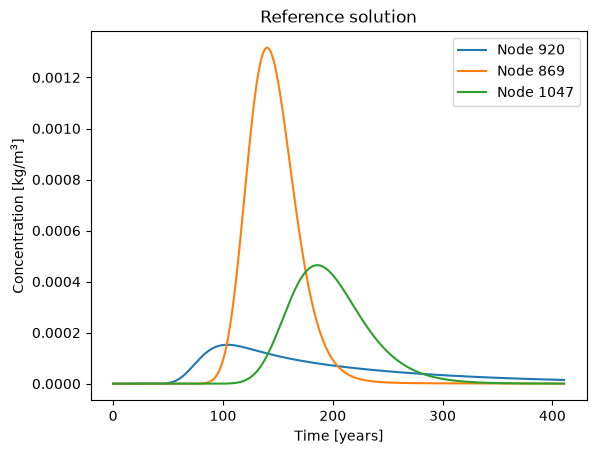

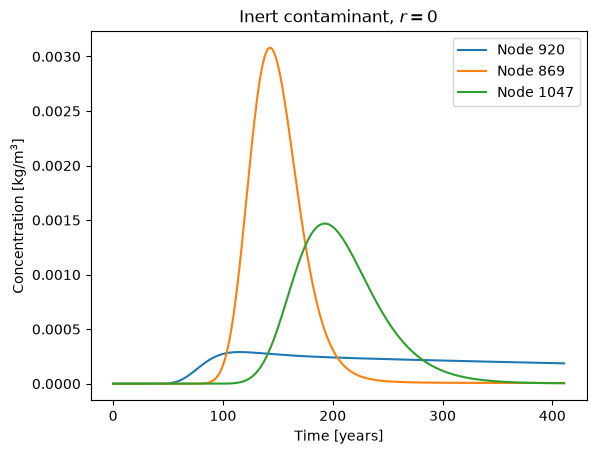

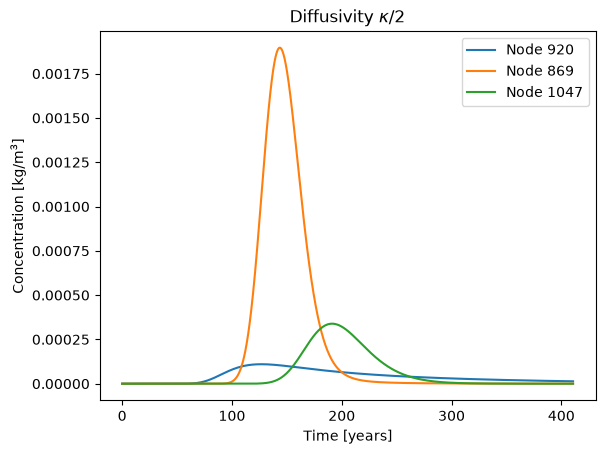

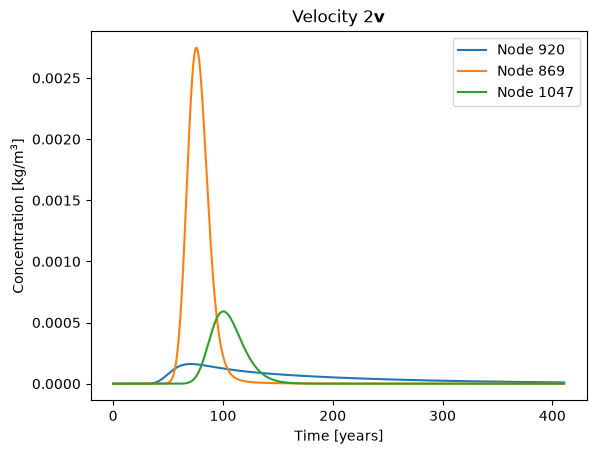

--- reference ---
node 920: peak 1.52e-04 kg/m3 at 104 yr, above critical value for 151 yr
node 869: peak 1.32e-03 kg/m3 at 140 yr, above critical value for 109 yr
node 1047: peak 4.64e-04 kg/m3 at 186 yr, above critical value for 137 yr
--- r = 0 ---
node 920: peak 2.90e-04 kg/m3 at 115 yr, above critical value for 344 yr
node 869: peak 3.08e-03 kg/m3 at 143 yr, above critical value for 133 yr
node 1047: peak 1.47e-03 kg/m3 at 193 yr, above critical value for 194 yr
--- kappa/2 ---
node 920: peak 1.10e-04 kg/m3 at 127 yr, above critical value for 116 yr
node 869: peak 1.90e-03 kg/m3 at 144 yr, above critical value for 94 yr
node 1047: peak 3.39e-04 kg/m3 at 191 yr, above critical value for 103 yr
--- 2v ---
node 920: peak 1.61e-04 kg/m3 at 71 yr, above critical value for 133 yr
node 869: peak 2.75e-03 kg/m3 at 76 yr, above critical value for 55 yr
node 1047: peak 5.91e-04 kg/m3 at 100 yr, above critical value for 64 yr


In [8]:
def plot_time_series(concentrations, nodes, dt_days, title):
    plt.figure()
    ts = dt_days/365.25 * np.arange(0,len(concentrations))
    for i in nodes:
        plt.plot(ts, concentrations[:,i],label='Node '+str(i))
    plt.ylabel('Concentration [kg/m$^3$]')
    plt.xlabel('Time [years]')
    plt.title(title)
    plt.legend()
    plt.show()

dt_days = 50

plot_time_series(concentrations, measurement_nodes, dt_days, 'Reference solution')

# Case 1: inert contaminant (no reaction/decay)
conc_r0 = simulate(velocities, reaction_rate=0)
plot_time_series(conc_r0, measurement_nodes, dt_days, 'Inert contaminant, $r=0$')

# Case 2: diffusivity reduced by a factor 2 (original r)
conc_kappa = simulate(velocities, diffusivity=2e-7/2)
plot_time_series(conc_kappa, measurement_nodes, dt_days, 'Diffusivity $\\kappa/2$')

# Case 3: groundwater velocity increased by a factor 2 (original r and kappa)
conc_v2 = simulate(2*velocities)
plot_time_series(conc_v2, measurement_nodes, dt_days, 'Velocity $2\\mathbf{v}$')

# Print peak values, time of peak and time above the critical value per node
critical_value = 0.00006
ts = dt_days/365.25 * np.arange(0, len(concentrations))
for name, conc in [('reference', concentrations), ('r = 0', conc_r0),
                   ('kappa/2', conc_kappa), ('2v', conc_v2)]:
    print(f'--- {name} ---')
    for i in measurement_nodes:
        k = np.argmax(conc[:, i])
        years_above = np.sum(conc[:, i] > critical_value) * dt_days / 365.25
        print(f'node {i}: peak {conc[k, i]:.2e} kg/m3 at {ts[k]:.0f} yr, '
              f'above critical value for {years_above:.0f} yr')

# Uncomment to inspect the spreading of the plume for each case
# pp.plot_concentration_interactive(nodes, connectivity, conc_r0, critical_value=critical_value, highlight_nodes=measurement_nodes)
# pp.plot_concentration_interactive(nodes, connectivity, conc_kappa, critical_value=critical_value, highlight_nodes=measurement_nodes)
# pp.plot_concentration_interactive(nodes, connectivity, conc_v2, critical_value=critical_value, highlight_nodes=measurement_nodes)

### Solution Task 4

**Where the measurement nodes are**
- Node 920 $(199, 82)$ lies in the **dead-end side pocket** at the top of the channel. There is (almost) no flow there, so contaminant can only get there by **diffusion**.
- Node 869 $(372, -8)$ lies in the **upper (short) arm** downstream of the spill, in the main flow path.
- Node 1047 $(372, -44)$ lies in the **lower (longer) arm** around the clay island, so the contaminant arrives later.

**Results** (critical value $6\cdot10^{-5}$ kg/m³)

| Case | Node 920: peak / time / years above crit. | Node 869: peak / time / years above crit. | Node 1047: peak / time / years above crit. |
|---|---|---|---|
| Reference | 1.5e-4 / 104 yr / 151 yr | 1.3e-3 / 140 yr / 109 yr | 4.6e-4 / 186 yr / 137 yr |
| $r = 0$ | 2.9e-4 / 115 yr / > 344 yr | 3.1e-3 / 143 yr / 133 yr | 1.5e-3 / 193 yr / 194 yr |
| $\kappa/2$ | 1.1e-4 / 127 yr / 117 yr | 1.9e-3 / 144 yr / 95 yr | 3.4e-4 / 191 yr / 103 yr |
| $2\mathbf{v}$ | 1.6e-4 / 71 yr / 134 yr | 2.7e-3 / 76 yr / 55 yr | 5.9e-4 / 100 yr / 64 yr |

**1. Inert contaminant ($r = 0$)**
- Without decay the contaminant mass is conserved, so concentrations are **higher everywhere**. The plume moves the same way, since advection and diffusion are unchanged, so arrival and peak times hardly change.
- The increase is larger for nodes that are reached later. Decay reduces concentrations by roughly $e^{-rt}$: at $t \approx 140$ yr this is $e^{-0.88} \approx 0.41$ (node 869 peak $\times 2.3$), and at $t\approx 190$ yr it is $e^{-1.2}\approx 0.30$ (node 1047 peak $\times 3.2$).
- In the dead-end pocket (node 920) the contaminant is trapped. It stays above the critical value until the end of the simulation because there is no decay to remove it.
- The total mass stays constant (about 17.6 kg/m) after the spill until the plume reaches the outflow boundary, and only then decreases.

**2. Diffusivity halved ($\kappa/2$)**
- Less spreading: the plume stays **narrower and more concentrated** and moves with the flow. In the main flow path (node 869) the peak is therefore **higher** (1.9e-3 vs 1.3e-3) and sharper, and the exceedance period is shorter. The arrival time of the peak is about the same, because advection controls the transport.
- Nodes that rely on spreading away from the main flow path receive **less** contaminant, and later: node 920 in the dead-end pocket is only reached by diffusion (peak 1.1e-4 vs 1.5e-4, first exceedance after 93 instead of 71 yr). Node 1047 in the lower arm also gets a lower peak.
- The total mass is practically the same as in the reference, because the spill and the decay are unchanged.
- Note: with less diffusion the problem becomes more advection-dominated (higher Péclet number), and small **negative concentrations** (numerical oscillations of the standard Galerkin method) appear near the plume front.

**3. Velocity doubled ($2\mathbf{v}$)**
- The plume is transported **about twice as fast**: peaks at nodes 869 and 1047 occur after about 76 and 100 yr instead of 140 and 186 yr.
- The peaks are **higher and narrower** for two reasons. There is less time for decay ($e^{-rt}$ is larger at earlier times), and less time for diffusion to spread the plume. The period above the critical value is roughly halved for nodes 869 and 1047.
- The contaminant leaves the domain through the outflow boundary much earlier, so the total mass drops after about 100 yr instead of about 200 yr.
- Node 920 (dead-end pocket) is only slightly affected: the concentration there is controlled by diffusion from the passing plume, which now passes earlier.

**Summary:** advection (the velocity) controls *when* the contaminant arrives, diffusion controls *how much the plume spreads* (to dead zones and side arms), and reaction controls *how much of it is left* when it arrives.

## Total mass of pollutant

The total mass in the system can be defined as an integral. 

$$
m = \int c\,\mathrm{d}\Omega
$$

In the function, there are routines for integration of stiffness matrices. Different integration schemes are used. A similar function can be used to evaluate the total mass $m$. 



> **Task 5**
>
> - Look at the different ways integration is performed in `getElementK`, `getElementC` and `getElementM`. Which of these approaches would you use for integrating $c$ over the domain? Reflect on why the different schemes are used for the different matrices. Recall that $c(x,y)$ is defined as $c(x,y) = \mathbf{N}(x,y)\mathbf{c}$ and that the shape functions in $\mathbf{N}$ are linear over each element, i.e. $ N_i(x,y) = A_ix + B_iy + C_i $ where $A_i$, $B_i$ and $C_i$ are constants that are different for each node and element. 
>
> - Implement the function `compute_elem_mass` below according to an appropriate integration scheme
>
> - Inspect the results of how the total mass of the pollutant in the system evolves over time. It should follow an exponential relation for a certain time window. Can you explain to which events in the simulation the bounds of this time window correspond? 


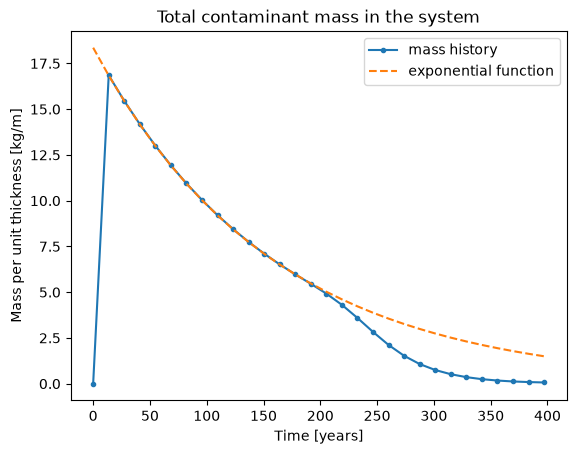

In [9]:
# function to compute the mass in the element
# inputs: node coordinates (n1, n2, n3) concentration vector at those nodes (element_c)
# output: mass integrated over the element 
def compute_elem_mass(n1, n2, n3, element_c):
    # c = N c is linear over the element, so a 1-point rule at the centroid
    # (weight = element area) integrates it exactly (same scheme as get_element_C).
    # c at the centroid = average of the three nodal values, since N(centroid) = [1/3, 1/3, 1/3]
    element_area = get_area(n1, n2, n3)
    c_centroid = np.mean(element_c)
    element_mass = element_area * c_centroid
    return element_mass

    # Alternative: 3-point midpoint rule (as in get_element_M). Also exact, but needs
    # 3 evaluations of N where 1 is enough for a linear integrand:
    # integration_locations = [(n1+n2)/2, (n2+n3)/2, (n3+n1)/2]
    # integration_weights = [element_area/3, element_area/3, element_area/3]
    # element_mass = 0
    # for x_ip, w_ip in zip(integration_locations, integration_weights):
    #     N_local = evaluate_N_matrix(x_ip, n1, n2, n3)
    #     element_mass += N_local @ element_c * w_ip
    # return element_mass

# function to compute the total mass in the system for given concentration vector
def compute_total_mass(concentration, connectivity, nodes):
    mass = 0
    for elnodes in connectivity:
        mass += compute_elem_mass(nodes[elnodes[0]], nodes[elnodes[1]], nodes[elnodes[2]], concentration[elnodes])
    return mass

# function to compute the total mass in the system over time
def compute_mass_evolution(concentrations, connectivity, nodes):
    total_mass = []
    i = 0
    for concentration in concentrations:
        total_mass.append ( compute_total_mass( concentration, connectivity, nodes) )
        i+=1
    return total_mass

skip = 100
dt_days = 50
ts = dt_days / 365.25 * np.arange(0,len(concentrations))
ts_jump = ts[0:-1:skip]
mass_history = compute_mass_evolution(concentrations[0:-1:skip], connectivity, nodes)

qtotal = 5000 * 24 * 60 * 60 * 2e-9 * 40.7 / 2
exponential = qtotal*np.exp(-2e-10*(ts_jump*24*60*60*365.25-2500*24*60*60))

plt.plot(ts_jump, mass_history, '.-', label='mass history')
plt.plot(ts_jump, exponential, '--', label='exponential function')
plt.ylabel('Mass per unit thickness [kg/m]')
plt.xlabel('Time [years]')
plt.title('Total contaminant mass in the system')
plt.legend()
plt.show()


### Solution Task 5

**Which integration scheme for $m = \int_\Omega c\,d\Omega$?**

The order of the integrand determines how many integration points are needed:

| Function | Integrand | Polynomial order | Scheme | Exact? |
|---|---|---|---|---|
| `get_element_K` | $\kappa\,\mathbf{B}^T\mathbf{B}$ | constant ($\mathbf{B}$ constant) | integrand $\times$ area, no integration points | yes |
| `get_element_C` | $\mathbf{N}^T\mathbf{v}^T\mathbf{B}$ | linear (only $\mathbf{N}$ varies) | 1 point (centroid), weight $A_e$ | yes |
| `get_element_M` | $\mathbf{N}^T\mathbf{N}$ | quadratic (linear $\times$ linear) | 3 points (edge midpoints), weights $A_e/3$ | yes |
| mass $m$ | $c = \mathbf{N}\mathbf{c}$ | **linear** | 1 point (centroid), weight $A_e$ | yes |

Each scheme uses the minimum number of points that is still exact. More points would give the same answer at a higher cost, and fewer points would give an error. The integrand $c = \mathbf{N}\mathbf{c}$ is linear, just like the integrand of $\mathbf{C}$, so we use **the same 1-point centroid rule as in `get_element_C`**. At the centroid, $\mathbf{N} = [\tfrac13, \tfrac13, \tfrac13]$, so:

$$
m_e = \int_{\Omega_e} \mathbf{N}\mathbf{c}_e\,d\Omega = A_e\,\mathbf{N}(\bar{\mathbf{x}})\,\mathbf{c}_e = A_e\,\frac{c_1+c_2+c_3}{3}
$$

The total mass is the sum over all elements, $m = \sum_e m_e$, which is done in `compute_total_mass`.
(Check: because $\sum_i N_i = 1$, this is also equal to the sum of all entries of $\mathbf{M}\mathbf{c}$, which gives identical numbers.)

**Mass history and the exponential window**

During the spill (first 5000 days $\approx$ 13.7 years) the mass increases, because contaminant enters through the Neumann boundary. After that, the computed mass follows the exponential curve (within 0.1%) until roughly **180 years**, after which it drops faster than the exponential.

- **Lower bound, $t = T = 5000$ days $\approx$ 13.7 yr: end of the spill.** After this moment $q = 0$, so no contaminant enters any more. The only thing that changes the mass is the reaction term. Integrating the PDE over the domain (with no boundary fluxes) gives
$$
\frac{dm}{dt} = -r\,m \quad\Rightarrow\quad m(t) = m_0\,e^{-r(t-t_0)}
$$
which is exponential decay. In the plotted function, $m_0 = $ `qtotal` $= \tfrac12 q_{max} T L_{spill}$ is the total injected mass and $t_0 = T/2 = 2500$ days. The injection pulse is symmetric around $T/2$, so the decay during the spill is approximately the same as if all mass had been injected at once at $t = T/2$.
- **Upper bound, $t \approx 180$ yr: the plume reaches the outflow boundary** at $x = 600$ m (concentration there exceeds $10^{-6}$ after about 166 yr and $10^{-5}$ after about 181 yr). From then on, contaminant also leaves the domain by advection through the right boundary, so the mass decreases faster than $e^{-rt}$ alone. At the end of the simulation almost all of the contaminant has left the domain or decayed.

> By Frans van der Meer, Delft University of Technology. CC BY 4.0, more info on the Credits page of Workbook. 